# Bài 09: Làm chủ PyTorch, Autograd và Huấn luyện Mạng MLP Phân loại Ảnh

## 1. Mục tiêu học tập
- Hiểu cách `PyTorch` quản lý `torch.Tensor`, thiết bị tính toán (`device`), và bộ máy tính đạo hàm tự động **`autograd`** (`requires_grad=True`, `.backward()`, `.grad`).
- Hiểu kiến trúc lớp cơ sở `torch.nn.Module`, cách tổ chức `Dataset` và `DataLoader`.
- Xây dựng mạng **MLP (`SimpleMLP`)** phân loại ảnh, thực hiện đầy đủ các tiêu chuẩn bắt buộc của mô hình Deep Learning:
  1. In tên model và tổng số tham số (`total`, `trainable`, `frozen`).
  2. In shape đầu vào/đầu ra và lập bảng chi tiết từng tầng (`layer_name`, `output_shape`, `params`).
  3. Viết tường minh vòng lặp huấn luyện (`Explicit Training Loop`) và kiểm định (`Validation Loop`).
  4. Lưu `checkpoint` tốt nhất dựa trên `Validation Loss`, nạp lại checkpoint và kiểm tra suy luận (`Inference`).
  5. Trực quan hóa các mẫu dự đoán **đúng** và **sai**.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 08 (hiểu Forward, Loss, Backward bằng NumPy).

## 3. Thời gian học dự kiến
- Khoảng **2.5 giờ** (ước tính).

## 4. Bài toán thực tế đơn giản
Thay vì tự viết tay công thức đạo hàm ngược dễ nhầm lẫn khi mạng có hàng chục tầng, ta dùng `PyTorch Autograd` để tự động ghi lại đồ thị tính toán trong lúc `forward` và tính toàn bộ đạo hàm chỉ bằng 1 lệnh `loss.backward()`, sau đó huấn luyện mạng `SimpleMLP` trên ảnh màu `(3, 32, 32)`.

## 5. Giải thích trực quan: Đồ thị Tính toán Động (`Dynamic Computation Graph`)
Khi bạn thực hiện phép toán `y = w * x + b` trên các Tensor có `requires_grad=True`:
- PyTorch âm thầm gắn vào `y` một thuộc tính `grad_fn` (ví dụ `<AddBackward0>`) trỏ ngược về `w`, `x`, `b`.
- Khi gọi `loss.backward()`, PyTorch đi ngược theo các mũi tên `grad_fn` từ `loss` về lá (`leaf tensors`) và cộng dồn đạo hàm $\frac{\partial \mathcal{L}}{\partial w}$ vào `w.grad`.

## 6. Thuật ngữ mới & Giải thích Keyword
| Keyword | Nghĩa tiếng Việt | Nhóm | Vai trò & Lưu ý quan trọng |
|---|---|---|---|
| `requires_grad=True` | Bật theo dõi đạo hàm | Huấn luyện | Báo cho `autograd` lưu lịch sử phép toán trên Tensor này. Mặc định các tham số trong `nn.Linear`, `nn.Conv2d` đều có `requires_grad=True`. |
| `optimizer.zero_grad()` | Xóa đạo hàm cũ về 0 | Huấn luyện | Phải gọi trước mỗi lần `loss.backward()` vì PyTorch mặc định cộng dồn (`+=`) đạo hàm mới vào `.grad` cũ. |
| `nn.CrossEntropyLoss()` | Hàm mất mát Cross-Entropy đa lớp | Huấn luyện | Nhận trực tiếp **`logits` thô `(B, C)`** và nhãn **`targets` kiểu `torch.long` `(B,)`**. Tuyệt đối không đặt `Softmax` trước hàm này! |
| `state_dict()` | Từ điển trọng số của mô hình | Triển khai | Lưu toàn bộ `weight`, `bias` và các buffer thống kê dưới dạng `OrderedDict` để ghi ra file `.pt`. |


In [1]:
# Cell 1: Kiểm chứng PyTorch Autograd — Đối chiếu đạo hàm tự động với đạo hàm tính tay
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

from src.utils import (
    set_seed,
    get_device,
    count_parameters,
    summarize_model_layers,
    save_checkpoint,
    load_checkpoint,
)
from src.synthetic_data import generate_synthetic_shapes_dataset
from src.models import SimpleMLP
from src.evaluation import compute_classification_metrics

QUICK_RUN = True
set_seed(42)
device = get_device()

# Kiểm tra Autograd trên công thức L(w) = (w * x - y)^2 ở Bài 04 (x=2, y=10, w=1 -> dL/dw = -32)
x_t = torch.tensor(2.0)
y_t = torch.tensor(10.0)
w_t = torch.tensor(1.0, requires_grad=True)

loss_t = (w_t * x_t - y_t) ** 2
loss_t.backward()
print(f"Loss = {loss_t.item():.1f} | grad_fn = {loss_t.grad_fn}")
print(f"Đạo hàm tự động w_t.grad = {w_t.grad.item():.1f} (Khớp tuyệt đối với -32.0 tính tay ở Bài 04!)")


Loss = 64.0 | grad_fn = <PowBackward0 object at 0x00000262C9AED2A0>
Đạo hàm tự động w_t.grad = -32.0 (Khớp tuyệt đối với -32.0 tính tay ở Bài 04!)


In [2]:
# Cell 2: Chuẩn bị Dataset, DataLoader (chuẩn hóa chỉ từ tập Train) và Bảng Tóm tắt Kiến trúc SimpleMLP
n_samples = 240 if QUICK_RUN else 480
ds = generate_synthetic_shapes_dataset(num_samples=n_samples, image_size=32, seed=42)
images_np = ds["images"]
labels_np = ds["labels"]
class_names = ds["class_names"]

idx_all = np.arange(len(images_np))
idx_tr, idx_temp = train_test_split(idx_all, test_size=0.30, random_state=42, stratify=labels_np)
idx_va, idx_te = train_test_split(idx_temp, test_size=0.50, random_state=42, stratify=labels_np[idx_temp])

# Chuyển sang NCHW float32 [0, 1] và tính mean, std CHỈ TRÊN TẬP TRAIN
X_all_t = torch.from_numpy(images_np).permute(0, 3, 1, 2).float() / 255.0
y_all_t = torch.from_numpy(labels_np).long()

train_mean = X_all_t[idx_tr].mean(dim=(0, 2, 3), keepdim=True)
train_std = X_all_t[idx_tr].std(dim=(0, 2, 3), keepdim=True) + 1e-6

X_norm_t = (X_all_t - train_mean) / train_std

train_loader = DataLoader(TensorDataset(X_norm_t[idx_tr], y_all_t[idx_tr]), batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(TensorDataset(X_norm_t[idx_va], y_all_t[idx_va]), batch_size=32, shuffle=False, num_workers=0)
test_loader = DataLoader(TensorDataset(X_norm_t[idx_te], y_all_t[idx_te]), batch_size=32, shuffle=False, num_workers=0)

model = SimpleMLP(in_channels=3, image_size=32, hidden_dim=128, num_classes=4, dropout_p=0.2).to(device)
param_info = count_parameters(model)
print(f"Tên mô hình: {model.__class__.__name__} | Thiết bị: {device}")
print(f"Số lượng tham số -> Tổng: {param_info['total']:,} | Trainable: {param_info['trainable']:,} | Frozen: {param_info['frozen']:,}")

layer_table = pd.DataFrame(summarize_model_layers(model, input_shape=(1, 3, 32, 32), device=device))
print("\n=== BẢNG KIẾN TRÚC LAYER, OUTPUT SHAPE VÀ SỐ THAM SỐ ===")
print(layer_table.to_string(index=False))


Tên mô hình: SimpleMLP | Thiết bị: cpu
Số lượng tham số -> Tổng: 402,116 | Trainable: 402,116 | Frozen: 0

=== BẢNG KIẾN TRÚC LAYER, OUTPUT SHAPE VÀ SỐ THAM SỐ ===
  layer_name layer_type output_shape  total_params  trainable_params
     flatten    Flatten    (1, 3072)             0                 0
classifier.0     Linear     (1, 128)        393344            393344
classifier.1  LayerNorm     (1, 128)           256               256
classifier.2       ReLU     (1, 128)             0                 0
classifier.3    Dropout     (1, 128)             0                 0
classifier.4     Linear      (1, 64)          8256              8256
classifier.5       ReLU      (1, 64)             0                 0
classifier.6     Linear       (1, 4)           260               260


In [3]:
# Cell 3: Viết Tường minh Vòng lặp Huấn luyện (Explicit Training Loop), Lưu & Nạp Checkpoint Tốt nhất
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

epochs = 12 if QUICK_RUN else 25
ckpt_path = project_root / "outputs" / "checkpoints" / "nb09_simple_mlp_best.pt"
preproc_cfg = {
    "image_size": 32,
    "mean": train_mean.squeeze().tolist(),
    "std": train_std.squeeze().tolist(),
}

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_loss = float("inf")

for epoch in range(1, epochs + 1):
    # --- 1. GIAI ĐOẠN TRAIN ---
    model.train()
    tr_loss_sum, tr_correct, tr_total = 0.0, 0, 0
    for x_b, y_b in train_loader:
        x_b, y_b = x_b.to(device), y_b.to(device)
        optimizer.zero_grad()
        logits = model(x_b)
        loss = criterion(logits, y_b)
        loss.backward()
        optimizer.step()

        tr_loss_sum += loss.item() * len(x_b)
        tr_correct += int((logits.argmax(dim=1) == y_b).sum().item())
        tr_total += len(x_b)

    # --- 2. GIAI ĐOẠN VALIDATION ---
    model.eval()
    va_loss_sum, va_correct, va_total = 0.0, 0, 0
    with torch.no_grad():
        for x_b, y_b in val_loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            logits = model(x_b)
            loss = criterion(logits, y_b)
            va_loss_sum += loss.item() * len(x_b)
            va_correct += int((logits.argmax(dim=1) == y_b).sum().item())
            va_total += len(x_b)

    tr_loss, tr_acc = tr_loss_sum / tr_total, tr_correct / tr_total
    va_loss, va_acc = va_loss_sum / va_total, va_correct / va_total
    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss)
    history["val_acc"].append(va_acc)

    if va_loss < best_val_loss:
        best_val_loss = va_loss
        save_checkpoint(
            filepath=ckpt_path,
            model=model,
            class_names=class_names,
            preprocessing_config=preproc_cfg,
            epoch=epoch,
            val_metrics={"loss": va_loss, "accuracy": va_acc},
            optimizer=optimizer,
        )

print(f"Đã lưu checkpoint tốt nhất tại: {ckpt_path.relative_to(project_root)} (Best Val Loss = {best_val_loss:.4f})")

# Nạp lại checkpoint tốt nhất và kiểm tra Inference trên tập Test
reloaded_model = SimpleMLP(in_channels=3, image_size=32, hidden_dim=128, num_classes=4).to(device)
ckpt_data = load_checkpoint(ckpt_path, model=reloaded_model, device=device)

reloaded_model.eval()
with torch.no_grad():
    test_logits = reloaded_model(X_norm_t[idx_te].to(device))
    test_probs = torch.softmax(test_logits, dim=1).cpu().numpy()
    test_preds = test_probs.argmax(axis=1)

test_metrics = compute_classification_metrics(labels_np[idx_te], test_preds, class_names)
print(f"Kết quả kiểm tra lại từ Checkpoint trên tập Test -> Accuracy: {test_metrics['accuracy']*100:.1f}%, Macro-F1: {test_metrics['macro_f1']:.3f}")


Đã lưu checkpoint tốt nhất tại: outputs\checkpoints\nb09_simple_mlp_best.pt (Best Val Loss = 1.1093)
Kết quả kiểm tra lại từ Checkpoint trên tập Test -> Accuracy: 41.7%, Macro-F1: 0.424


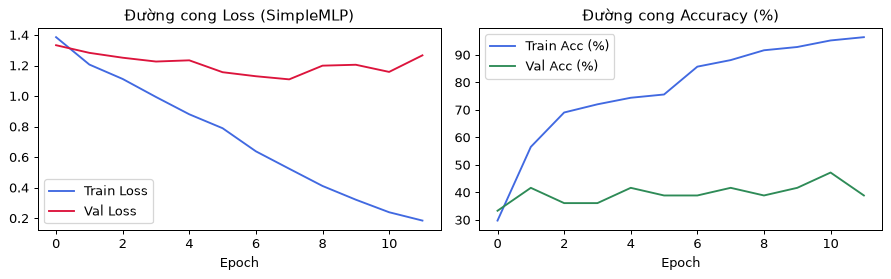

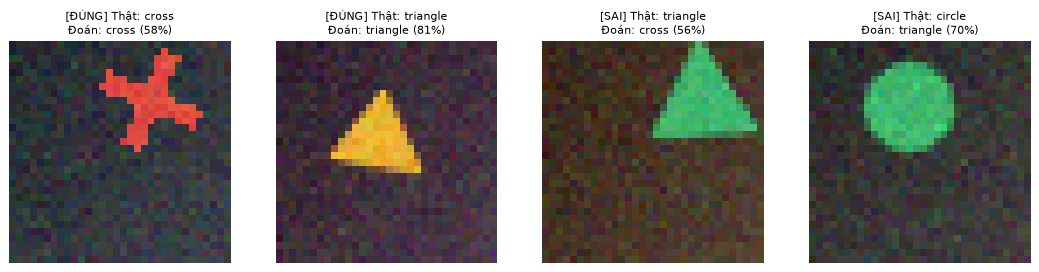

In [4]:
# Cell 4: Vẽ Đường cong Loss/Accuracy và Hiển thị Dự đoán Đúng / Sai trên tập Test
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(history["train_loss"], label="Train Loss", color="royalblue")
axes[0].plot(history["val_loss"], label="Val Loss", color="crimson")
axes[0].set_title("Đường cong Loss (SimpleMLP)")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot([a * 100 for a in history["train_acc"]], label="Train Acc (%)", color="royalblue")
axes[1].plot([a * 100 for a in history["val_acc"]], label="Val Acc (%)", color="seagreen")
axes[1].set_title("Đường cong Accuracy (%)")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

# Hiển thị mẫu dự đoán đúng và mẫu dự đoán sai (nếu có)
y_te_true = labels_np[idx_te]
correct_mask = test_preds == y_te_true
correct_indices = np.where(correct_mask)[0][:2]
wrong_indices = np.where(~correct_mask)[0][:2]
vis_indices = list(correct_indices) + list(wrong_indices)

fig, axes = plt.subplots(1, len(vis_indices), figsize=(3.0 * len(vis_indices), 3.0))
if len(vis_indices) == 1:
    axes = [axes]
for ax, local_i in zip(axes, vis_indices):
    orig_img = images_np[idx_te[local_i]]
    t_cls = class_names[y_te_true[local_i]]
    p_cls = class_names[test_preds[local_i]]
    conf = test_probs[local_i, test_preds[local_i]] * 100
    status = "ĐÚNG" if y_te_true[local_i] == test_preds[local_i] else "SAI"
    ax.imshow(orig_img)
    ax.set_title(f"[{status}] Thật: {t_cls}\nĐoán: {p_cls} ({conf:.0f}%)", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


## 11. Nhận xét cách đọc kết quả
- Nhìn vào **Bảng kiến trúc ở Cell 2**: Tầng `Linear` đầu tiên (`classifier.0`) chiếm tới `3072 * 128 + 128 = 393,344` tham số (chiếm **97.8%** tổng số tham số của toàn mạng!), chỉ vì nó nối mỗi pixel trong `3072` kênh-điểm ảnh với mọi nơ-ron ẩn.
- Hạn chế lớn nhất của `MLP` trên ảnh: Khi dịch chuyển hình tròn sang phải vài pixel, vị trí các phần tử trong vector trải phẳng `3072` chiều thay đổi hoàn toàn. Đó là lý do bài tiếp theo (**Bài 10: CNN**) sẽ dùng phép tích chập chia sẻ trọng số để giảm số tham số đi hơn 15 lần mà độ chính xác lại cao hơn!

## 12 & 14. Thí nghiệm và Bài tập tự làm
- **Cơ bản**: So sánh tốc độ hội tụ của `SimpleMLP` khi dùng bộ tối ưu `SGD(lr=0.01)` so với `AdamW(lr=1e-3)`.
- **Trung cấp**: Kiểm tra xem điều gì xảy ra nếu khi suy luận trên ảnh có `dropout_p=0.5`, bạn quên gọi `model.eval()` và chạy dự đoán 5 lần liên tiếp trên cùng 1 bức ảnh.
- **Nâng cao**: Đóng băng tầng `classifier.0` (`requires_grad = False`) và đếm lại số lượng `trainable` vs `frozen` parameters bằng hàm `count_parameters`.

## 15. Gợi ý và Lời giải


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho Thí nghiệm & Bài tập Bài 09
# 1. Cơ bản: So sánh SGD vs AdamW trong 5 epochs
for opt_name, make_opt in [
    ("SGD (lr=0.01)", lambda params: torch.optim.SGD(params, lr=0.01, momentum=0.9)),
    ("AdamW (lr=1e-3)", lambda params: torch.optim.AdamW(params, lr=1e-3)),
]:
    set_seed(42)
    m_tmp = SimpleMLP(3, 32, 64, 4).to(device)
    opt_tmp = make_opt(m_tmp.parameters())
    for _ in range(5):
        m_tmp.train()
        for xb, yb in train_loader:
            opt_tmp.zero_grad()
            loss_b = criterion(m_tmp(xb.to(device)), yb.to(device))
            loss_b.backward()
            opt_tmp.step()
    m_tmp.eval()
    with torch.no_grad():
        va_acc_tmp = (m_tmp(X_norm_t[idx_va].to(device)).argmax(1).cpu() == y_all_t[idx_va]).float().mean().item()
    print(f"[Cơ bản] {opt_name:16s} -> Val Acc sau 5 epochs: {va_acc_tmp*100:.1f}%")

# 2. Trung cấp: Hậu quả của việc quên gọi model.eval() khi có Dropout
m_drop = SimpleMLP(3, 32, 64, 4, dropout_p=0.5).to(device)
sample_one = X_norm_t[idx_te[:1]].to(device)
m_drop.train()  # Cố tình để ở chế độ train
preds_train_mode = [round(float(m_drop(sample_one)[0, 0].item()), 4) for _ in range(4)]
m_drop.eval()   # Chuyển sang chế độ eval chuẩn
preds_eval_mode = [round(float(m_drop(sample_one)[0, 0].item()), 4) for _ in range(4)]
print("[Trung cấp] Logit lớp 0 khi QUÊN model.eval() (nhảy loạn):", preds_train_mode)
print("[Trung cấp] Logit lớp 0 khi CÓ model.eval() (nhất quán)  :", preds_eval_mode)

# 3. Nâng cao: Đóng băng tầng đầu tiên và đếm lại tham số
for p in m_drop.classifier[0].parameters():
    p.requires_grad = False
print("[Nâng cao] Tham số sau khi đóng băng tầng Linear đầu:", count_parameters(m_drop))


[Cơ bản] SGD (lr=0.01)    -> Val Acc sau 5 epochs: 33.3%
[Cơ bản] AdamW (lr=1e-3)  -> Val Acc sau 5 epochs: 36.1%
[Trung cấp] Logit lớp 0 khi QUÊN model.eval() (nhảy loạn): [0.0738, -0.1324, 0.2176, 0.388]
[Trung cấp] Logit lớp 0 khi CÓ model.eval() (nhất quán)  : [0.0599, 0.0599, 0.0599, 0.0599]
[Nâng cao] Tham số sau khi đóng băng tầng Linear đầu: {'total': 199012, 'trainable': 2340, 'frozen': 196672}


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Đã thành thạo `Tensor`, `autograd`, `Dataset`, `DataLoader` và quy trình lưu/nạp `checkpoint` chuẩn.
- [x] Đã thấy hạn chế bùng nổ tham số của `MLP` trên dữ liệu ảnh 2D.
- [x] Sẵn sàng chuyển sang **Bài 10: `10_cnn_from_scratch.ipynb`** để khám phá kiến trúc Mạng Tích chập (CNN)!

## 17. Nguồn tham khảo
- Paszke, A. et al. (2019), *PyTorch: An Imperative Style, High-Performance Deep Learning Library*, NeurIPS.
- PyTorch Autograd Mechanics: https://pytorch.org/docs/stable/notes/autograd.html
